# STATE Codex r1 — 01 Basal transcriptomic distance

**Run All executes the complete source → input features → released-score metrics → condition-level analysis → curves chain.** The four notebooks share source downloads, but default Run All **recalculates** derived features, released-score errors and all analyses even if computed tables exist. Original public inputs are downloaded if absent and checksum verified before reuse. The separate pipeline CLI offers `--reuse-computed` only for deliberately requested receipt-verified reuse; these notebook defaults do not use it. A cold run requires the documented environment, network access, disk space and CPU time; execute on exxact05 for this reconstruction.

The model outputs are the original released STATE predictions. Recomputing their per-condition full-feature log2-fold-change RMSE requires no new neural inference. Archived five-context means and fitted summaries are comparison targets only; they do not enter the calculations below.

Surviving original methods are preserved byte-for-byte. Continuation methods are reconstructed from the original report and native commands. The declared bootstrap seed, axis-standardization population and quintile-matching implementation are recorded explicitly; they were not selected by fitting the historical answers. See [method details](../methods/METHODS.md), [source manifest](../methods/sources.json), [pipeline](../methods/run_pipeline.py), and [original report](../recovery/original_handoff/REPORT.md).

## 1. Data acquisition

The manifest pins the CMP expression archive, DepMap 23Q4 metadata/expression, original training-context map, Tahoe cell metadata and official ST-HVG `eval_best` prediction/observation files. SHA-256 verification happens before use. Source downloads can be reused after checksum verification; each notebook default recalculates its shared derived stages.

In [1]:
from pathlib import Path
import importlib.util, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, JSON
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'methods/sources.json').is_file())
spec=importlib.util.spec_from_file_location('state_notebook_workflow',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
INPUTS=ROOT/'inputs'
FEATURES=ROOT/'computed/features'
ANALYSIS=ROOT/'computed/analysis'
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)
source_manifest=json.loads((ROOT/'methods/sources.json').read_text())
source_rows=pd.DataFrame(source_manifest['inputs']).drop_duplicates('path')
display(source_rows[['path','bytes','sha256','url']])
print('Unique public source files:',len(source_rows))
print('Declared source bytes:',int(source_rows.bytes.sum()))
print('Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.')


,path,bytes,sha256,url
0,acquisition/DepMap_Model_23Q4.csv,530469,6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341,https://ndownloader.figshare.com/files/43746708
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,449782440,d8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8,https://ndownloader.figshare.com/files/43347204
2,acquisition/cmp_rnaseq_all_20220624.zip,940707972,2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a,https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip
3,acquisition/tahoe_obs_metadata.parquet,2293981573,e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe,https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b00654...
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,517889,44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e...
5,acquisition/official_scores_st_se/C32_pred_de.csv,388384053,7169a2f135657b9f1db7440a9c7feef3f759428b0783f4fc89ac1c48ccac4d76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
6,acquisition/official_scores_st_se/C32_results.csv,468674,cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
7,acquisition/official_scores_st_se/C32_agg_results.csv,3547,5a88c0744b9d31bfa73dcbcbe2d3366b7779f3e334d3a74be0bc7d6a8a53ca76,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
8,acquisition/official_scores/C32_real_de.csv,387383572,19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...
9,acquisition/official_scores_st_se/HOP62_pred_de.csv,393288407,5db83d0ef3c96cbcfc9f61dd1e851e5e4f2661a22fe831638e80741036ecc594,https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b...


Unique public source files: 55
Declared source bytes: 11545305551
Run All recalculates features, released-score errors and analyses below. Existing public downloads are reused only after checksum verification.


## 2. Processing

The pipeline applies the original atlas method to source matrices and computes actual released-score errors. The original code selects 2,000 high-variance genes from mapped training contexts, applies training mean/sample-SD standardization, and takes the median of five nearest RMS distances. This follows the code’s actual gene selection; no extra gene filter is added from prose.

In [2]:
# Actual source acquisition / verification, input processing, released-score reduction,
# condition-level regressions and curves, even when derived outputs already exist.
wf.run_pipeline(ROOT)
wf.show_receipts(ROOT)
wf.source_functions(ROOT,'methods/original/01_build_prospective_axis.py',['choose_primary_genes','panel_distance'])
mapping=wf.read_csv(ROOT,'computed/features/cell_line_mapping.csv')
primary=wf.read_csv(ROOT,'computed/features/primary_cmp_distances.csv')
independent=wf.read_csv(ROOT,'computed/features/independent_ccle_distances.csv')
display(mapping.head(12));display(primary);display(independent)


Recalculating source → features → released-score metrics → analysis. Existing source downloads are checksum verified before reuse.
Running download_inputs.py


{"event": "start", "files": 55, "bytes": 11545305551, "destination": "/ewsc/yektefai/spectra_runs/state_codex_r1_reconstruction_20261109/inputs"}


{"event": "verified", "completed": 1, "path": "acquisition/DepMap_Model_23Q4.csv", "bytes": 530469}
{"event": "verified", "completed": 2, "path": "acquisition/state_tahoe_cell_type_onehot_map_verified.pkl", "bytes": 517889}


{"event": "verified", "completed": 3, "path": "acquisition/official_scores_st_se/C32_pred_de.csv", "bytes": 388384053}
{"event": "verified", "completed": 4, "path": "acquisition/official_scores_st_se/C32_results.csv", "bytes": 468674}
{"event": "verified", "completed": 5, "path": "acquisition/official_scores_st_se/C32_agg_results.csv", "bytes": 3547}


{"event": "verified", "completed": 6, "path": "acquisition/official_scores/C32_real_de.csv", "bytes": 387383572}


{"event": "verified", "completed": 7, "path": "acquisition/official_scores_st_se/HOP62_pred_de.csv", "bytes": 393288407}
{"event": "verified", "completed": 8, "path": "acquisition/official_scores_st_se/HOP62_results.csv", "bytes": 463111}
{"event": "verified", "completed": 9, "path": "acquisition/official_scores_st_se/HOP62_agg_results.csv", "bytes": 3526}


... (53 outputs left out)

def panel_distance(
    expression: pd.DataFrame,
    train_ids: list[str],
    test_ids: list[str],
    k: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    train = expression.loc[train_ids]
    test = expression.loc[test_ids]
    means = train.mean(axis=0)
    scales = train.std(axis=0, ddof=1).replace(0, np.nan)
    valid = scales.notna() & np.isfinite(scales)
    train_z = (train.loc[:, valid] - means[valid]) / scales[valid]
    test_z = (test.loc[:, valid] - means[valid]) / scales[valid]
    pairwise = np.sqrt(
        ((test_z.to_numpy()[:, None, :] - train_z.to_numpy()[None, :, :]) ** 2).mean(axis=2)
    )
    pairwise_df = pd.DataFrame(pairwise, index=test_ids, columns=train_ids)
    k_eff = min(k, len(train_ids))
    summary = pd.DataFrame(
        {
            "sample_id": test_ids,
            "distance": np.median(np.sort(pairwise, axis=1)[:, :k_eff], axis=1),
            "nearest_distance": pairwise.min(axis=1),
            "nearest_training_id": pairwise_df.idxmin(axis=1).to_numpy(),
            "n_genes": int(valid.sum()),
            "n_training_contexts": len(train_ids),
            "k_neighbors": k_eff,
        }
    )
    return summary, pairwise_df

,cell_line,held_out,lookup_name,depmap_id,match_status,candidate_ids,DepMap_ID,stripped_cell_line_name,CCLE_Name,Sanger_Model_ID,lineage,lineage_subtype
0,A-172,False,A-172,ACH-000558,exact,ACH-000558,ACH-000558,A172,A172_CENTRAL_NERVOUS_SYSTEM,SIDM00799,CNS/Brain,Glioblastoma
1,A-427,False,A-427,ACH-000757,exact,ACH-000757,ACH-000757,A427,A427_LUNG,SIDM00810,Lung,Lung Adenocarcinoma
2,A498,False,A498,ACH-000555,exact,ACH-000555,ACH-000555,A498,A498_KIDNEY,SIDM00124,Kidney,Renal Cell Carcinoma
3,A549,False,A549,ACH-000681,exact,ACH-000681,ACH-000681,A549,A549_LUNG,SIDM00903,Lung,Lung Adenocarcinoma
4,AN3 CA,False,AN3 CA,ACH-000940,exact,ACH-000940,ACH-000940,AN3CA,AN3CA_ENDOMETRIUM,SIDM00901,Uterus,Endometrial Carcinoma
5,AsPC-1,False,AsPC-1,ACH-000222,exact,ACH-000222,ACH-000222,ASPC1,ASPC1_PANCREAS,SIDM00899,Pancreas,Pancreatic Adenocarcinoma
6,BT-474,False,BT-474,ACH-000927,exact,ACH-000927,ACH-000927,BT474,BT474_BREAST,SIDM00963,Breast,Breast Invasive Ductal Carcinoma
7,C-33 A,False,C-33 A,ACH-001333,exact,ACH-001333,ACH-001333,C33A,C33A_CERVIX,SIDM00889,Cervix,Cervical Squamous Cell Carcinoma
8,C32,True,C32,ACH-000580,exact,ACH-000580,ACH-000580,C32,C32_SKIN,SIDM00890,Skin,Melanoma
9,CFPAC-1,False,CFPAC-1,ACH-000138,exact,ACH-000138,ACH-000138,CFPAC1,CFPAC1_PANCREAS,SIDM00130,Pancreas,Pancreatic Adenocarcinoma


,distance,nearest_distance,nearest_training_id,n_genes,n_training_contexts,k_neighbors,cell_line,depmap_id,Sanger_Model_ID,lineage,lineage_subtype,rank_near_to_far
0,0.953059,0.929317,SIDM00693,2000,44,5,HOP62,ACH-000861,SIDM00133,Lung,Lung Adenocarcinoma,1
1,1.062149,0.938547,SIDM00138,2000,44,5,PANC-1,ACH-000164,SIDM00610,Pancreas,Pancreatic Adenocarcinoma,2
2,1.131635,1.067178,SIDM01138,2000,44,5,Hs 766T,ACH-000178,SIDM00664,Pancreas,Pancreatic Adenocarcinoma,3
3,1.254312,1.063818,SIDM00082,2000,44,5,C32,ACH-000580,SIDM00890,Skin,Melanoma,4
4,1.404170,1.358120,SIDM00840,2000,44,5,HepG2/C3A,ACH-001021,SIDM01237,Liver,Hepatoblastoma,5


,distance,nearest_distance,nearest_training_id,n_genes,n_training_contexts,k_neighbors,cell_line,depmap_id,proxy_used,rank_near_to_far
0,0.995532,0.915471,ACH-000396,1832,43,5,HOP62,ACH-000861,False,1
1,1.087685,0.962865,ACH-000900,1832,43,5,PANC-1,ACH-000164,False,2
2,1.196330,1.102091,ACH-000139,1832,43,5,Hs 766T,ACH-000178,False,3
3,1.264095,1.033076,ACH-001190,1832,43,5,C32,ACH-000580,False,4
4,1.363152,1.309835,ACH-000842,1832,43,5,HepG2/C3A,ACH-000739,True,5


## 3. Axis

The axis is reconstructed entirely from reference expression and the training-context mapping. Independent CCLE distance is computed separately, including the explicitly documented parental HepG2 proxy. These values then join the per-condition scores.

In [3]:
AXIS='distance'
conditions=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/per_condition_scores.csv')
axis=conditions[['cell_line','axis_value','distance_z']].drop_duplicates().sort_values('axis_value')
assert axis.cell_line.is_unique
display(axis)


,cell_line,axis_value,distance_z
1136,HOP62,0.953059,-1.333121
4544,PANC-1,1.062149,-0.634017
3408,Hs 766T,1.131635,-0.188711
0,C32,1.254312,0.597464
2272,HepG2/C3A,1.404170,1.557829


## 4. Levels and eligibility

Near-to-far levels follow the calculated input-side axis. Drug-dose targets must occur in all five contexts, and parent compounds need at least two doses. The original SHA-256 parent-compound partition keeps all contexts/doses together. Eligibility is calculated from the real released rows, not forced to the historical count.

In [4]:
levels=axis.copy();levels.insert(0,'level',np.arange(1,len(levels)+1));display(levels)
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['normalize_compound','partition_for'])
wf.source_functions(ROOT,'methods/reconstruct.py',['build_condition_table'])
eligibility=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/compound_eligibility.csv')
display(eligibility.head(12));wf.show_conditions(conditions)


,level,cell_line,axis_value,distance_z
1136,1,HOP62,0.953059,-1.333121
4544,2,PANC-1,1.062149,-0.634017
3408,3,Hs 766T,1.131635,-0.188711
0,4,C32,1.254312,0.597464
2272,5,HepG2/C3A,1.404170,1.557829


**Executed helper:** `methods/original/04_analyze_frozen_axis.py::normalize_compound`

def normalize_compound(value: str) -> str:
    return re.sub(r"[^a-z0-9]+", "", value.lower())

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::partition_for`

def partition_for(compound: str) -> str:
    bucket = int(hashlib.sha256(compound.encode("utf-8")).hexdigest()[:16], 16) % 10
    return "discovery" if bucket <= 2 else "confirmation"

**Executed helper:** `methods/reconstruct.py::build_condition_table`

def build_condition_table(scores_dir,real_dir,cell_counts,axis,*,axis_z_scope,scored_rows=None):
    """Original04 score+eligibility joins; explicit continuation z convention.

    scores_dir supplies <context>_pred_de.csv and _results.csv; real_dir
    supplies _real_de.csv. Reuse of HVG observed rows is supported by final
    integrity_checks.json, but callers must verify those hashes beforehand.
    axis requires cell_line, axis_value. Cell counts require target,
    cell_line,n_cells_full,n_cells_all (original.extract_cell_counts).
    """
    m=original_scoring();scores_dir=Path(scores_dir);real_dir=Path(real_dir)
    axis=pd.read_csv(axis) if isinstance(axis,(str,Path)) else axis.copy()
    counts=pd.read_csv(cell_counts) if isinstance(cell_counts,(str,Path)) else cell_counts.copy()
    if scored_rows is None:scored_rows=score_released_outputs(scores_dir,real_dir)
    all_rows=scored_rows.merge(axis,on='cell_line',validate='many_to_one')
    if len(all_rows)!=len(scored_rows):raise ValueError('Axis merge discarded released rows')
    all_rows=all_rows.merge(counts,on=['cell_line','target'],how='left',validate='one_to_one')
    parsed=all_rows.target.map(m.parse_target)
    all_rows['compound_name']=parsed.map(lambda x:x[0]);all_rows['dose']=parsed.map(lambda x:x[1]);all_rows['dose_unit']=parsed.map(lambda x:x[2])
    all_rows['compound']=all_rows.compound_name.map(m.normalize_compound)
    all_rows['partition']=all_rows.compound.map(m.partition_for)
    all_rows['n_cells']=all_rows.n_cells_full.where(all_rows.n_cells_full>0,all_rows.n_cells_all)
    all_rows['log_n_cells']=np.log1p(all_rows.n_cells);all_rows['log_n_de']=np.log1p(all_rows.n_de)
    coverage=all_rows.groupby('target').cell_line.nunique()
    common=all_rows.loc[all_rows.target.isin(coverage[coverage==5].index)].copy()
    eligibility=common.groupby('compound').agg(n_contexts=('cell_line','nunique'),n_doses=('dose','nunique'),n_targets=('target','nunique'),partition=('partition','first'))
    eligible=eligibility.index[(eligibility.n_contexts==5)&(eligibility.n_doses>=2)]
    common=common.loc[common.compound.isin(eligible)].copy()
    if common.n_cells.isna().any():raise ValueError('Missing original condition cell counts')
    populations={'all_rows':all_rows,'eligible_all':common,'confirmation':common.loc[common.partition=='confirmation'],'contexts':axis}
    if axis_z_scope not in populations:raise ValueError('axis_z_scope must explicitly be all_rows, eligible_all, confirmation, or contexts')
    values=populations[axis_z_scope].axis_value
    mu,sd=values.mean(),values.std(ddof=1)
    if not np.isfinite(sd) or sd<=0:raise ValueError('Degenerate axis')
    common['distance_z']=(common.axis_value-mu)/sd
    common.attrs['axis_standardization']={'scope':axis_z_scope,'mean':float(mu),'sample_sd':float(sd)}
    return common,eligibility,all_rows

,compound,n_contexts,n_doses,n_targets,partition
0,18glycyrrhetinicacid,5,3,3,discovery
1,4egi1,5,3,3,discovery
2,5azacytidine,5,3,3,confirmation
3,5fluorouracil,5,3,3,confirmation
4,8hydroxyquinoline,5,3,3,confirmation
5,9ing41,5,3,3,confirmation
6,abemaciclib,5,3,3,discovery
7,abirateroneacetate,5,3,3,confirmation
8,acetazolamide,5,3,3,discovery
9,acetohexamide,5,3,3,discovery


,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,1.254312,1.956152,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,1.254312,2.236865,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,1.254312,1.716199,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,1.254312,1.947983,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,1.254312,2.034995,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,1.254312,2.173920,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,1.254312,2.204911,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,1.254312,2.301442,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,1.254312,1.907020,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,1.254312,2.272496,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 5. Model / released scores

The original full-feature scorer aligns released observed/predicted feature rows and evaluates log2 fold changes. STATE RMSE is `sqrt(mean((predicted − observed)²))`; the no-effect reference is `sqrt(mean(observed²))`. Observed FDR<0.05 yields the DE count; cell counts supply the same-example adjustment. The following code and condition rows are the actual calculation route.

In [5]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['compute_lfc_scores'])
wf.show_conditions(conditions)


**Executed helper:** `methods/original/04_analyze_frozen_axis.py::compute_lfc_scores`

def compute_lfc_scores(real_path: Path, pred_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    use_real = ["target", "feature", "fold_change", "fdr"]
    use_pred = ["target", "feature", "fold_change"]
    real_iter = pd.read_csv(real_path, usecols=use_real, chunksize=chunksize)
    pred_iter = pd.read_csv(pred_path, usecols=use_pred, chunksize=chunksize)
    accum: dict[str, list[float]] = {}
    total_rows = 0
    for real, pred in zip(real_iter, pred_iter, strict=True):
        if len(real) != len(pred):
            raise RuntimeError("real/pred DE chunk length mismatch")
        if not np.array_equal(real["target"].to_numpy(), pred["target"].to_numpy()):
            raise RuntimeError("real/pred DE target order mismatch")
        if not np.array_equal(real["feature"].to_numpy(), pred["feature"].to_numpy()):
            raise RuntimeError("real/pred DE feature order mismatch")
        real_lfc = np.log2(real["fold_change"].to_numpy(dtype=float))
        pred_lfc = np.log2(pred["fold_change"].to_numpy(dtype=float))
        if not (np.isfinite(real_lfc).all() and np.isfinite(pred_lfc).all()):
            raise RuntimeError("non-finite released fold change encountered")
        temp = pd.DataFrame(
            {
                "target": real["target"].to_numpy(),
                "state_sq": (pred_lfc - real_lfc) ** 2,
                "identity_sq": real_lfc**2,
                "is_de": real["fdr"].to_numpy(dtype=float) < 0.05,
                "n": 1,
            }
        )
        grouped = temp.groupby("target", sort=False).agg(
            state_sse=("state_sq", "sum"),
            identity_sse=("identity_sq", "sum"),
            n_de=("is_de", "sum"),
            n_genes=("n", "sum"),
        )
        for target, row in grouped.iterrows():
            current = accum.setdefault(target, [0.0, 0.0, 0.0, 0.0])
            current[0] += float(row["state_sse"])
            current[1] += float(row["identity_sse"])
            current[2] += float(row["n_de"])
            current[3] += float(row["n_genes"])
        total_rows += len(real)
    result = pd.DataFrame(
        [
            {
                "target": target,
                "state_lfc_rmse": math.sqrt(values[0] / values[3]),
                "identity_lfc_rmse": math.sqrt(values[1] / values[3]),
                "n_de": int(values[2]),
                "n_genes_lfc": int(values[3]),
            }
            for target, values in accum.items()
        ]
    )
    if int(result["n_genes_lfc"].sum()) != total_rows:
        raise RuntimeError("DE row accounting mismatch")
    return result

,target,cell_line,compound,partition,dose,axis_value,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",C32,rverapamilhydrochloride,discovery,0.05,1.254312,1.956152,1.743597,320,2095
1,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",C32,rverapamilhydrochloride,discovery,0.50,1.254312,2.236865,2.060241,427,1077
2,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",C32,rverapamilhydrochloride,discovery,5.00,1.254312,1.716199,1.415155,531,4029
3,"[('(S)-Crizotinib', 0.05, 'uM')]",C32,scrizotinib,confirmation,0.05,1.254312,1.947983,1.950492,526,1835
4,"[('(S)-Crizotinib', 0.5, 'uM')]",C32,scrizotinib,confirmation,0.50,1.254312,2.034995,2.000006,220,1347
5,"[('(S)-Crizotinib', 5.0, 'uM')]",C32,scrizotinib,confirmation,5.00,1.254312,2.173920,2.117408,283,964
6,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.05,1.254312,2.204911,2.079753,306,1139
7,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",C32,18glycyrrhetinicacid,discovery,0.50,1.254312,2.301442,2.134732,341,875
8,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",C32,18glycyrrhetinicacid,discovery,5.00,1.254312,1.907020,1.683020,310,2474
9,"[('4EGI-1', 0.05, 'uM')]",C32,4egi1,discovery,0.05,1.254312,2.272496,1.918225,489,1380


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


Every displayed observation is a real context × released drug-dose target, not an expanded aggregate mean.


## 6. Regressions, curves and controls

Raw and adjusted regressions use within-drug-dose centering and parent-compound clustered inference. Target and reference bootstrap draws use the same compound multiplicities. Curves first average doses within parent compound/context and then weight compounds equally. Error bars are recomputed from those compound observations. Matching, dose strata, leave-one-context-out and independent-atlas fits are also executed; the declared reconstructed matching rule remains labeled.

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::within_design`

def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::fit_within`

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }

**Executed helper:** `methods/original/04_analyze_frozen_axis.py::context_spc`

def context_spc(frame: pd.DataFrame, reps: int, seed: int) -> pd.DataFrame:
    compound_context = frame.groupby(["compound", "cell_line"], as_index=False).agg(
        state_lfc_rmse=("state_lfc_rmse", "mean"),
        identity_lfc_rmse=("identity_lfc_rmse", "mean"),
        distance=("distance", "first"),
        ccle_distance=("ccle_distance", "first"),
        n_conditions=("target", "nunique"),
    )
    compounds = sorted(compound_context["compound"].unique())
    rng = np.random.default_rng(seed)
    rows = []
    for cell, group in compound_context.groupby("cell_line"):
        indexed = group.set_index("compound")
        state_values = indexed.loc[compounds, "state_lfc_rmse"].to_numpy()
        reference_values = indexed.loc[compounds, "identity_lfc_rmse"].to_numpy()
        state_boot = np.empty(reps)
        reference_boot = np.empty(reps)
        for i in range(reps):
            sample = rng.integers(0, len(compounds), len(compounds))
            state_boot[i] = state_values[sample].mean()
            reference_boot[i] = reference_values[sample].mean()
        rows.append(
            {
                "cell_line": cell,
                "distance": group["distance"].iloc[0],
                "ccle_distance": group["ccle_distance"].iloc[0],
                "n_compounds": len(compounds),
                "n_conditions": int(group["n_conditions"].sum()),
                "state_rmse_mean": state_values.mean(),
                "state_rmse_ci_low": np.quantile(state_boot, 0.025),
                "state_rmse_ci_high": np.quantile(state_boot, 0.975),
                "identity_rmse_mean": reference_values.mean(),
                "identity_rmse_ci_low": np.quantile(reference_boot, 0.025),
                "identity_rmse_ci_high": np.quantile(reference_boot, 0.975),
            }
        )
    return pd.DataFrame(rows).sort_values("distance")

... (5 outputs left out)

,recomputed_diagnostic
state_raw_positive,False
state_adjusted_positive,False
context_order_rho_at_least_point70,False
all_dose_adjusted_positive,False
all_leave_one_context_out_adjusted_positive,False


Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.


,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95,status,reconstructed_method,method,cutpoint_scope
0,models / state_raw,-0.032213,0.005239,1.000000e+00,7.793156e-10,4020.0,804.0,268.0,[],"[-0.04254994885774676, -0.022016928105237407]",NaN,NaN,NaN,NaN,NaN
1,models / state_adjusted,-0.150035,0.004976,1.000000e+00,9.903387e-200,4020.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.15951551154128896, -0.1398012127844341]",NaN,NaN,NaN,NaN,NaN
2,models / identity_raw,0.163206,0.004507,2.105473e-287,4.210945e-287,4020.0,804.0,268.0,[],"[0.15451658381991967, 0.17208150746334852]",NaN,NaN,NaN,NaN,NaN
3,paired_state_minus_identity,-0.195419,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.20156880125316654, -0.18916182491813147]",NaN,NaN,NaN,NaN
4,dose_sensitivity / 0.05,-0.152905,0.006052,1.000000e+00,8.134430e-141,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
5,dose_sensitivity / 0.5,-0.134063,0.008170,1.000000e+00,1.620053e-60,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
6,dose_sensitivity / 5.0,-0.159950,0.006809,1.000000e+00,4.866489e-122,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
7,leave_one_context_out / C32,-0.128584,0.005732,1.000000e+00,1.811768e-111,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
8,leave_one_context_out / HOP62,-0.269291,0.007472,1.000000e+00,1.887108e-284,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN
9,leave_one_context_out / HepG2/C3A,-0.094577,0.004762,1.000000e+00,8.576509e-88,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN,NaN,NaN,NaN,NaN


,cell_line,distance,ccle_distance,n_compounds,n_conditions,state_rmse_mean,state_rmse_ci_low,state_rmse_ci_high,identity_rmse_mean,identity_rmse_ci_low,identity_rmse_ci_high
0,HOP62,0.953059,NaN,268,804,2.215137,2.195162,2.235822,1.680951,1.655997,1.706377
1,PANC-1,1.062149,NaN,268,804,2.326216,2.298377,2.354071,1.553926,1.526577,1.581677
2,Hs 766T,1.131635,NaN,268,804,2.398761,2.362932,2.435912,1.821537,1.781326,1.863767
3,C32,1.254312,NaN,268,804,2.143416,2.123034,2.164235,1.961917,1.933713,1.989548
4,HepG2/C3A,1.404170,NaN,268,804,2.206718,2.181271,2.231859,2.062156,2.030132,2.094043


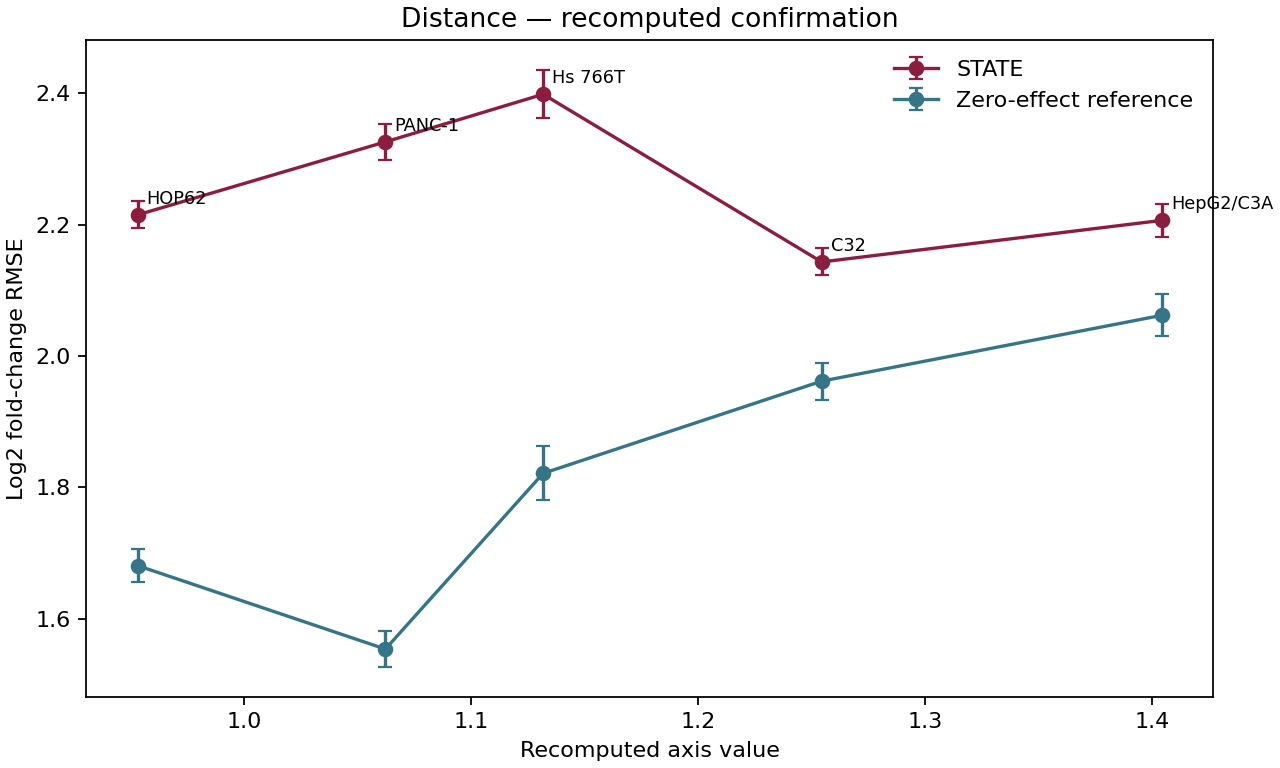

,effect_quintile,cell_count_quintile,C32,HOP62,HepG2/C3A,Hs 766T,PANC-1
0,0,2,0,0,0,0,1
1,0,3,6,24,20,19,60
2,0,4,37,171,19,149,298
3,1,1,0,0,1,0,0
4,1,2,8,27,42,42,46
5,1,3,80,160,36,102,151
6,1,4,12,47,0,15,35
7,2,0,0,0,2,0,0
8,2,1,9,21,71,40,26
9,2,2,153,130,46,88,74


Matching rows: 4020 — inspect full assignment/weights in the linked CSV.


,target,overlap_at_N,overlap_at_50,overlap_at_100,overlap_at_200,overlap_at_500,precision_at_N,precision_at_50,precision_at_100,precision_at_200,...,effect_quintile,cell_count_quintile,effect_q_1,effect_q_2,effect_q_3,effect_q_4,cells_q_1,cells_q_2,cells_q_3,cells_q_4
0,"[('(S)-Crizotinib', 0.05, 'uM')]",0.427757,0.04,0.07,0.125,0.416000,0.496599,0.04,0.07,0.125,...,3,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,"[('(S)-Crizotinib', 0.5, 'uM')]",0.136364,0.10,0.09,0.120,0.136364,0.241379,0.10,0.09,0.120,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,"[('(S)-Crizotinib', 5.0, 'uM')]",0.236749,0.02,0.04,0.150,0.236749,0.339667,0.02,0.04,0.150,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,"[('5-Azacytidine', 0.05, 'uM')]",0.248603,0.08,0.07,0.110,0.248603,0.400691,0.08,0.07,0.110,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,"[('5-Azacytidine', 0.5, 'uM')]",0.357798,0.02,0.06,0.100,0.357798,0.449235,0.02,0.06,0.100,...,4,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5,"[('5-Azacytidine', 5.0, 'uM')]",0.187845,0.06,0.03,0.085,0.187845,0.340336,0.06,0.03,0.085,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
6,"[('5-Fluorouracil', 0.05, 'uM')]",0.242991,0.06,0.06,0.105,0.242991,0.323851,0.06,0.06,0.105,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
7,"[('5-Fluorouracil', 0.5, 'uM')]",0.397778,0.00,0.02,0.135,0.397778,0.463040,0.00,0.02,0.135,...,3,1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
8,"[('5-Fluorouracil', 5.0, 'uM')]",0.180822,0.06,0.08,0.100,0.180822,0.298999,0.06,0.08,0.100,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
9,"[('8-Hydroxyquinoline', 0.05, 'uM')]",0.166090,0.00,0.04,0.130,0.166090,0.240000,0.00,0.04,0.130,...,2,2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


**Independent-atlas sensitivity:** `ccle_analysis.json`

,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,-0.023415,0.004538,1.0,2.473825e-07,4020.0,804.0,268.0,[],"[-0.03232141833551465, -0.014454778505619591]",NaN
1,models / state_adjusted,-0.129623,0.005339,1.0,3.249077e-130,4020.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.13984976403795132, -0.11872820599805779]",NaN
2,models / identity_raw,0.164998,0.003481,0.0,0.000000e+00,4020.0,804.0,268.0,[],"[0.1583014484592723, 0.17182814738518234]",NaN
3,paired_state_minus_identity,-0.188413,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.19444479862524278, -0.18225605618284912]"
4,dose_sensitivity / 0.05,-0.129797,0.006375,1.0,3.792664e-92,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,-0.114604,0.008056,1.0,6.292892e-46,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,-0.140906,0.007177,1.0,8.219273e-86,1340.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,-0.097491,0.006242,1.0,5.468471e-55,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,-0.306896,0.008941,1.0,3.462909e-258,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / HepG2/C3A,-0.078860,0.004662,1.0,3.461328e-64,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


**Independent-atlas sensitivity:** `ccle_exact_contexts_analysis.json`

,analysis,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,bootstrap_ci95,ci95
0,models / state_raw,-0.010601,0.003378,9.991510e-01,1.697932e-03,3216.0,804.0,268.0,[],"[-0.017266598971421607, -0.0038611534572938378]",NaN
1,models / state_adjusted,-0.078860,0.004662,1.000000e+00,3.461328e-64,3216.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']","[-0.08811643035478556, -0.06960214245444395]",NaN
2,models / identity_raw,0.155328,0.001730,0.000000e+00,0.000000e+00,3216.0,804.0,268.0,[],"[0.15201271943547967, 0.1587075762501301]",NaN
3,paired_state_minus_identity,-0.165930,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[-0.17175043337515, -0.1600560585579502]"
4,dose_sensitivity / 0.05,-0.085816,0.006601,1.000000e+00,1.205786e-38,1072.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
5,dose_sensitivity / 0.5,-0.065272,0.007212,1.000000e+00,1.420828e-19,1072.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
6,dose_sensitivity / 5.0,-0.086249,0.006927,1.000000e+00,1.391599e-35,1072.0,268.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
7,leave_one_context_out / C32,0.063688,0.009715,2.772047e-11,5.544095e-11,2412.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
8,leave_one_context_out / HOP62,-0.316787,0.011482,1.000000e+00,1.438846e-167,2412.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN
9,leave_one_context_out / Hs 766T,-0.005212,0.006680,7.823709e-01,4.352582e-01,2412.0,804.0,268.0,"['identity_lfc_rmse', 'log_n_de', 'log_n_cells']",NaN,NaN


In [6]:
wf.source_functions(ROOT,'methods/original/04_analyze_frozen_axis.py',['within_design','fit_within','context_spc'])
wf.source_functions(ROOT,'methods/reconstruct.py',['bootstrap_slopes_fast','quintile_matching'])
analysis=wf.read_json(ROOT,f'computed/analysis/{AXIS}/analysis.json')
display(JSON(analysis['policy']))
display(pd.Series(analysis['computed_diagnostics'],name='recomputed_diagnostic').to_frame())
print('Main displayed fits: confirmation partition; discovery/all fits remain in analysis.json.')
fits=wf.show_fits(analysis['partitions']['confirmation'])
curve=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/spc_table.csv')
display(curve)
wf.show_curve(ROOT,AXIS)
strata=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_strata.csv')
weights=wf.read_csv(ROOT,f'computed/analysis/{AXIS}/matching_weights.csv')
display(strata)
print('Matching rows:',len(weights),'— inspect full assignment/weights in the linked CSV.')
display(weights.head(10))
for filename in ['ccle_analysis.json','ccle_exact_contexts_analysis.json']:
    display(Markdown('**Independent-atlas sensitivity:** `'+filename+'`'))
    wf.show_fits(wf.read_json(ROOT,f'computed/analysis/{AXIS}/{filename}'))


## 7. Historical result and decision

Compare the newly calculated coefficients/curves with the recorded result. The original agent rejected this candidate because STATE error decreased with greater distance, including adjusted and sensitivity fits. Any numerical reconstruction difference remains visible rather than changing the input panel or method to obtain the original answer.

In [7]:
comparison=wf.historical_comparison(ROOT,'distance')
wf.original_decision(ROOT,'basal_transcriptomic_distance','Historical finding: the proposed worsening ran in the opposite direction. The computed raw, adjusted, independent-atlas and control estimates above show the corresponding reconstructed evidence.')


,axis,metric,historical,recomputed,difference,tolerance,within_tolerance,note
0,distance,state_raw,-0.032210,-0.032213,-3.147093e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
1,distance,state_adjusted,-0.150040,-0.150035,4.982223e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
2,distance,identity_raw,0.163210,0.163206,-4.053477e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
3,distance,quintile_matching,-0.124780,-0.127852,-3.072327e-03,NaN,NaN,Original eight quintile-control columns and full-row inclusion recovered; partition-specific cut...
4,distance,confirmation_rows,4020.000000,4020.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
5,distance,confirmation_targets,804.000000,804.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
6,distance,confirmation_compounds,268.000000,268.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
7,distance,confirmation_contexts,5.000000,5.000000,0.000000e+00,0.000000e+00,True,Reported rounded value; no calculation choice is changed to obtain agreement.
25,distance,ccle_adjusted,-0.129620,-0.129623,-3.357546e-06,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.
26,distance,ccle_exact_contexts_adjusted,-0.078860,-0.078860,4.088709e-07,5.000000e-05,True,Reported rounded value; no calculation choice is changed to obtain agreement.


Historical values are validation targets only. Differences are reported rather than used to tune inputs or calculations.


**Original decision:** `axis_negative_opposite_direction`

Historical finding: the proposed worsening ran in the opposite direction. The computed raw, adjusted, independent-atlas and control estimates above show the corresponding reconstructed evidence.

Historical overall disposition: CLOSED_NEGATIVE_NO_CERTIFIED_GENERALIZABILITY_FAILURE
This records the original agent determination; it does not create a new scientific certification.
